# Assignment 1: Data Profiling (EDA) Report

**Team members**

| No. | Name | Matric No. |
|---|---|---|
| 1 | NUREEN HADIRAH BINTI MOHD SABRI  | A209341 |
| 2 |  NURUL IZYANI BINTI MOHD IZYAN | A210813 |
| 3 | NUR ALIEYA BALQISH BINTI NOR AZMAN | A210192 |
| 4 | NUR NABIHAH BINTI ALWI | A210814 |

## How to run this notebook

1. Put `Assignment1_Data_Profiling.ipynb` and `student_sleep_screen_time_academic_performance.csv` in the **same folder** (both are in this repository).
2. Install the libraries if needed: `pip install pandas numpy matplotlib seaborn`.
3. Open the notebook in Jupyter or Google Colab (upload the CSV to the Colab session first) and choose **Run All** (Kernel > Restart & Run All).
4. The notebook runs from top to bottom and saves `student_sleep_screen_time_cleaned.csv` at the end.

## 1. Scenario

A university wants to understand whether students' sleep habits and screen time (especially screen use just before bed) are linked to sleep quality and academic performance (CGPA). The data fits this assignment because it contains missing values, impossible or extreme values, inconsistent formats (gender labels, bedtime recorded across midnight), and sensitive fields (student ID, age, gender), with some small groups that raise bias risks.

**Questions to answer:**
1. Is the data clean and reliable enough to study sleep, screen time and CGPA?
2. Which quality problems (missing values, outliers, inconsistent formats, invalid values) must be fixed first, and how?
3. What PII and bias risks must be handled before any analysis is shared?

## 2. Data Source

- **Dataset:** Student Sleep, Screen Time and Academic Performance
- **Platform:** Kaggle
- **URL:** https://www.kaggle.com/datasets/aamir28/student-sleep-screen-time-and-academic-performance
- **How it was obtained:** The CSV file was downloaded manually from the Kaggle dataset page (Download button) and saved in the same folder as this notebook. The file is `student_sleep_screen_time_academic_performance.csv` (500 rows, 25 columns).
- **Note:** The student IDs are sequential (STU2001, STU2002, ...), so the data may be simulated or a survey sample. This is treated as a limitation in the conclusion.

## 3. Data Profiling and Issue Handling

### 3.0 Load and inspect the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

df = pd.read_csv("student_sleep_screen_time_academic_performance.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (500, 25)


,student_id,age,gender,year_of_study,major_category,residence_type,chronotype,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,pre_sleep_screen_time_min,daily_screen_time_hours,primary_device,device_free_before_bed,caffeine_drinks_per_day,naps_per_week,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,has_part_time_job,semester_type,cgpa
0,STU2001,21,Male,3,Humanities,With Family,Early Bird,22.3,7.6,2.0,12,7.1,Tablet,No,2,0,10.0,7,5.0,7.0,15.6,80.0,No,Spring,2.99
1,STU2002,20,Female,2,STEM,Dormitory,Intermediate,23.1,5.9,2.7,49,5.7,Laptop,Yes,1,3,7.0,3,6.0,7.0,17.5,78.9,No,Summer,2.88
2,STU2003,20,Male,4,Social Sciences,With Family,Intermediate,23.4,8.4,1.8,22,2.3,Smartphone,No,2,1,9.0,2,5.0,1.0,19.0,69.7,Yes,Spring,3.15
3,STU2004,22,F,1,Humanities,Off-campus Apartment,Night Owl,0.9,5.1,2.4,32,4.8,Laptop,No,1,3,6.0,4,3.0,7.0,7.3,59.1,No,Fall,2.27
4,STU2005,23,Female,4,Social Sciences,Off-campus Apartment,Early Bird,23.4,5.9,2.0,27,4.5,Smartphone,No,4,2,7.0,6,8.0,3.0,23.6,79.9,No,Summer,2.74


In [2]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 25 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   student_id                 500 non-null    object 
 1   age                        500 non-null    int64  
 2   gender                     500 non-null    object 
 3   year_of_study              500 non-null    int64  
 4   major_category             500 non-null    object 
 5   residence_type             500 non-null    object 
 6   chronotype                 500 non-null    object 
 7   avg_bedtime_hour           500 non-null    float64
 8   avg_sleep_hours_weekday    500 non-null    float64
 9   weekend_sleep_delta_hours  500 non-null    float64
 10  pre_sleep_screen_time_min  500 non-null    int64  
 11  daily_screen_time_hours    500 non-null    float64
 12  primary_device             500 non-null    object 
 13  device_free_before_bed     491 non-null    object 

,count,mean,std,min,25%,50%,75%,max
age,500.0,20.260000,1.994079,17.00,19.000,20.00,22.000,27.00
year_of_study,500.0,2.954000,1.405644,1.00,2.000,3.00,4.000,5.00
avg_bedtime_hour,500.0,12.778200,10.772656,0.00,1.100,21.50,22.800,24.00
avg_sleep_hours_weekday,500.0,6.608200,1.435784,1.50,5.700,6.60,7.700,10.50
weekend_sleep_delta_hours,500.0,1.540600,0.965441,-1.00,0.900,1.50,2.200,4.40
pre_sleep_screen_time_min,500.0,38.388000,23.573478,0.00,22.000,35.50,54.000,240.00
daily_screen_time_hours,500.0,5.827000,2.046193,0.50,4.475,5.80,7.200,19.50
caffeine_drinks_per_day,500.0,1.502000,1.273279,0.00,1.000,1.00,2.000,7.00
naps_per_week,500.0,1.458000,1.331082,0.00,0.000,1.00,2.000,7.00
sleep_quality_score,494.0,7.271255,2.131409,1.00,6.000,7.00,9.000,10.00


### 3.1 Missing values

First we measure where values are missing and how much. The chart below is a missing-value heatmap (each yellow line is one missing cell).

                          Missing  Percent (%)
energy_level                   15          3.0
concentration_difficulty       14          2.8
device_free_before_bed          9          1.8
cgpa                            7          1.4
sleep_quality_score             6          1.2


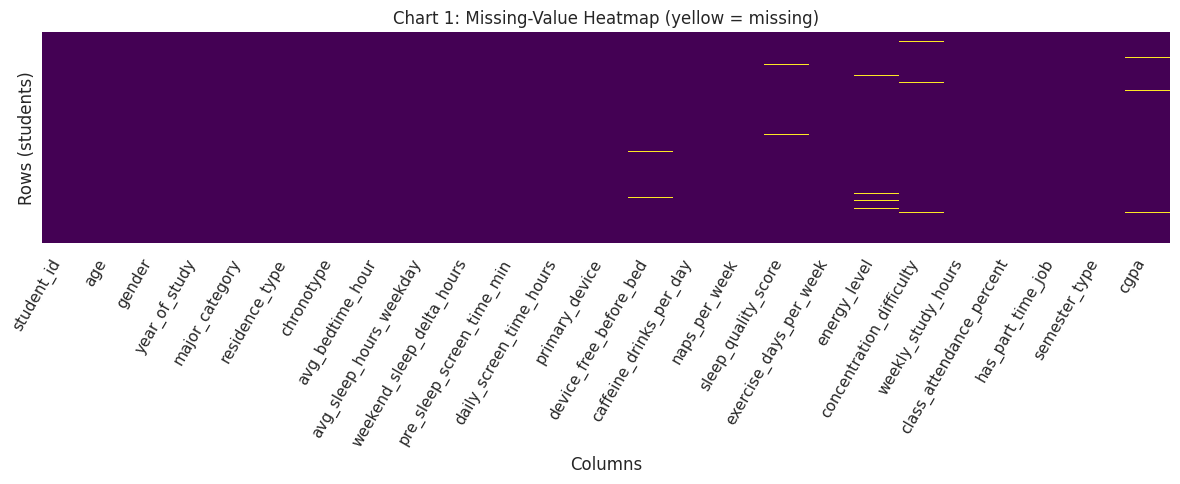

In [3]:
missing = df.isnull().sum()
missing_table = pd.DataFrame({
    "Missing": missing,
    "Percent (%)": (missing / len(df) * 100).round(1)
})
missing_table = missing_table[missing_table["Missing"] > 0].sort_values("Missing", ascending=False)
print(missing_table)

# Chart 1: missing-value heatmap
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Chart 1: Missing-Value Heatmap (yellow = missing)")
plt.xlabel("Columns")
plt.ylabel("Rows (students)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

**Observation:** Five columns have missing values, each between 1.2% and 3.0% (`energy_level` 3.0%, `concentration_difficulty` 2.8%, `cgpa` 1.4%, `device_free_before_bed` 1.8%, `sleep_quality_score` 1.2%). The missing cells appear scattered across rows, with no block of empty rows.

**Handling decisions and reasons:**
- `cgpa` (7 rows): **dropped.** CGPA is the academic outcome we want to study. Filling it with a guess would invent the outcome and weaken any relationship we test. Dropping only 1.4% of rows loses very little data.
- `sleep_quality_score`, `energy_level`, `concentration_difficulty` (numeric, 1-10 scales): **imputed with the median and flagged.** The median is not affected by extreme values, and the missing share is small. A flag column (`*_was_missing`) keeps a record of which values were filled in.
- `device_free_before_bed` (Yes/No): **filled with "Unknown".** Using the most common value ("No", 75%) would assume an answer the student never gave. A separate "Unknown" category is more honest.

In [4]:
# Evidence for the "Unknown" decision: share of each answer before filling
print(df["device_free_before_bed"].value_counts(normalize=True).round(3))
print()

df_clean = df.copy()

# (a) Drop rows where the outcome (cgpa) is missing
before = len(df_clean)
df_clean = df_clean.dropna(subset=["cgpa"]).copy()
print("Rows dropped because cgpa is missing:", before - len(df_clean))

# (b) Flag + median imputation for numeric scale columns
for col in ["sleep_quality_score", "energy_level", "concentration_difficulty"]:
    df_clean[col + "_was_missing"] = df_clean[col].isnull()
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# (c) Categorical: separate "Unknown" category
df_clean["device_free_before_bed"] = df_clean["device_free_before_bed"].fillna("Unknown")

print("Missing values left:", df_clean.isnull().sum().sum())
print("Shape after handling missing values:", df_clean.shape)

device_free_before_bed
No     0.749
Yes    0.251
Name: proportion, dtype: float64

Rows dropped because cgpa is missing: 7
Missing values left: 0
Shape after handling missing values: (493, 28)


### 3.2 Other quality issues

We check duplicates, inconsistent categories, wrong formats and invalid values.

In [5]:
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate student IDs:", df_clean["student_id"].duplicated().sum())

print("\nRaw gender labels:")
print(df["gender"].value_counts())

Duplicate rows: 0
Duplicate student IDs: 0

Raw gender labels:
gender
Female               190
Male                 180
male                  30
female                28
F                     24
M                     23
Non-binary            13
Prefer not to say     12
Name: count, dtype: int64


**Duplicates:** none found, so nothing was removed.

**Inconsistent categories (gender):** the same group is written in several ways (`Female`, `female`, `F`, `Male`, `male`, `M`). If left as is, the analysis would treat them as 8 different groups. We standardise them into 4 clean labels. The chart below compares before and after.

In [6]:
for col in ["residence_type", "chronotype", "has_part_time_job",
            "semester_type", "primary_device", "major_category"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


residence_type:
residence_type
Dormitory               190
Off-campus Apartment    153
With Family             133
Homestay                 24
Name: count, dtype: int64

chronotype:
chronotype
Intermediate    201
Early Bird      152
Night Owl       147
Name: count, dtype: int64

has_part_time_job:
has_part_time_job
No     331
Yes    169
Name: count, dtype: int64

semester_type:
semester_type
Fall      225
Spring    201
Summer     74
Name: count, dtype: int64

primary_device:
primary_device
Smartphone    271
Laptop        198
Tablet         31
Name: count, dtype: int64

major_category:
major_category
STEM               162
Business            89
Social Sciences     77
Health Sciences     62
Humanities          52
Arts                33
Law                 25
Name: count, dtype: int64


**Other categorical columns:** the labels in these columns are consistent, so no changes were needed.

Unmapped gender values: 0


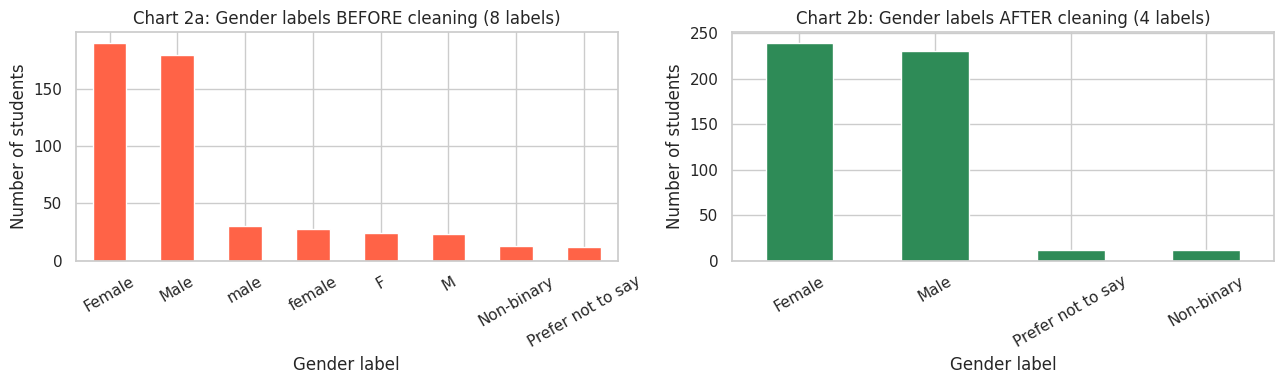

In [7]:
gender_map = {
    "m": "Male", "male": "Male",
    "f": "Female", "female": "Female",
    "non-binary": "Non-binary",
    "prefer not to say": "Prefer not to say",
}
df_clean["gender"] = df_clean["gender"].str.strip().str.lower().map(gender_map)
print("Unmapped gender values:", df_clean["gender"].isnull().sum())

# Chart 2: inconsistent categories before vs after
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df["gender"].value_counts().plot(kind="bar", ax=axes[0], color="tomato")
axes[0].set_title("Chart 2a: Gender labels BEFORE cleaning (8 labels)")
axes[0].set_xlabel("Gender label")
axes[0].set_ylabel("Number of students")
df_clean["gender"].value_counts().plot(kind="bar", ax=axes[1], color="seagreen")
axes[1].set_title("Chart 2b: Gender labels AFTER cleaning (4 labels)")
axes[1].set_xlabel("Gender label")
axes[1].set_ylabel("Number of students")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Inconsistent format (bedtime):** `avg_bedtime_hour` mixes evening times (22.3, 23.4) with after-midnight times (0.9, 1.6). To the computer, 0.9 looks like a very early bedtime instead of 12:54 am. This makes the mean (12.8) and standard deviation (10.8) meaningless, and the IQR method cannot detect outliers correctly. The histogram shows two separate groups.

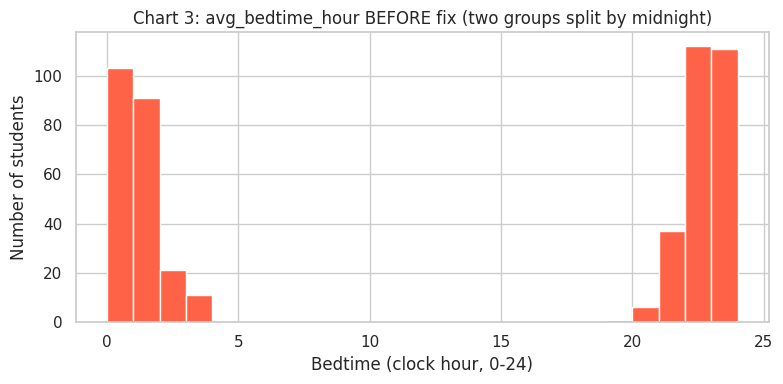

Before fix -> mean: 12.82, std: 10.78
After fix  -> mean: 23.82, std: 1.47


In [8]:
# Chart 3: bedtime histogram before the fix
plt.figure(figsize=(8, 4))
plt.hist(df_clean["avg_bedtime_hour"], bins=24, color="tomato", edgecolor="white")
plt.title("Chart 3: avg_bedtime_hour BEFORE fix (two groups split by midnight)")
plt.xlabel("Bedtime (clock hour, 0-24)")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

print("Before fix -> mean: %.2f, std: %.2f" % (df_clean["avg_bedtime_hour"].mean(), df_clean["avg_bedtime_hour"].std()))

# Fix: times before noon are after-midnight bedtimes, so add 24 (e.g. 0.9 -> 24.9)
df_clean["bedtime_hour_continuous"] = np.where(
    df_clean["avg_bedtime_hour"] < 12,
    df_clean["avg_bedtime_hour"] + 24,
    df_clean["avg_bedtime_hour"],
)
print("After fix  -> mean: %.2f, std: %.2f" % (df_clean["bedtime_hour_continuous"].mean(), df_clean["bedtime_hour_continuous"].std()))

After the fix, bedtime is on one continuous scale (24 = midnight, 25 = 1 am) with a sensible mean of about 23.8 and a standard deviation of about 1.5. The original column is kept for reference.

**Invalid / inconsistent values:** we check ranges and logical rules.

In [9]:
checks = {
    "Age outside 16-100": ((df_clean["age"] < 16) | (df_clean["age"] > 100)).sum(),
    "Sleep hours outside 0-24": ((df_clean["avg_sleep_hours_weekday"] < 0) | (df_clean["avg_sleep_hours_weekday"] > 24)).sum(),
    "CGPA outside 0-4": ((df_clean["cgpa"] < 0) | (df_clean["cgpa"] > 4)).sum(),
    "Attendance outside 0-100": ((df_clean["class_attendance_percent"] < 0) | (df_clean["class_attendance_percent"] > 100)).sum(),
    "Scores (1-10) outside range": (
        (df_clean[["sleep_quality_score", "energy_level", "concentration_difficulty"]] < 1) |
        (df_clean[["sleep_quality_score", "energy_level", "concentration_difficulty"]] > 10)
    ).sum().sum(),
    "Pre-sleep screen time > total daily screen time": (df_clean["pre_sleep_screen_time_min"] / 60 > df_clean["daily_screen_time_hours"]).sum(),
    "Negative weekend sleep delta (sleep less on weekends)": (df_clean["weekend_sleep_delta_hours"] < 0).sum(),
}
for name, n in checks.items():
    print(f"{name}: {n}")

# Logical consistency: age vs year of study
# Implied age at entry = age - (year_of_study - 1). Entering university before 16 is not realistic.
df_clean["age_year_inconsistent"] = (df_clean["age"] - (df_clean["year_of_study"] - 1)) < 16
print("\nRows where age and year_of_study do not fit together:", df_clean["age_year_inconsistent"].sum())
print("Students aged under 18:", (df_clean["age"] < 18).sum())

Age outside 16-100: 0
Sleep hours outside 0-24: 0
CGPA outside 0-4: 0
Attendance outside 0-100: 0
Scores (1-10) outside range: 0
Pre-sleep screen time > total daily screen time: 0
Negative weekend sleep delta (sleep less on weekends): 21

Rows where age and year_of_study do not fit together: 56
Students aged under 18: 41


**Findings and decisions:**
- All range checks pass (no CGPA above 4, no attendance above 100, scores stay between 1 and 10), so no value was removed for being out of range.
- **Negative weekend sleep delta (21 rows):** sleeping less on weekends is possible, so these values are **kept** as valid.
- **Age vs year of study (56 rows):** for example, a 17-year-old in year 5 would have started university at age 13. We cannot tell whether `age` or `year_of_study` is wrong, so the rows are **kept but flagged** in `age_year_inconsistent` and should be treated carefully in later analysis.
- **Data types:** all types suit their columns (numbers are numeric, categories are text). `student_id` stays as text because it is an identifier, not a number.

### 3.3 Outliers

We use the **IQR method** (values below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR) on the continuous columns. Discrete count columns and fixed-scale scores (caffeine, naps, 1-10 scores) are excluded, because their extreme values are real answers on a limited scale. The boxplots show the outliers.

                   Column  Lower bound  Upper bound  # below  # above   Min    Max
  avg_sleep_hours_weekday         2.70        10.70        2        0  1.50  10.50
weekend_sleep_delta_hours        -1.05         4.15        0        1 -1.00   4.40
pre_sleep_screen_time_min       -26.00       102.00        0        3  0.00 240.00
  daily_screen_time_hours         0.45        11.25        0        2  0.50  19.50
       weekly_study_hours        -0.10        32.70        0        3  0.00  88.50
 class_attendance_percent        45.25       113.65        2        0 36.90 100.00
                     cgpa         1.98         3.69        2        4  1.89   3.95
  bedtime_hour_continuous        19.15        28.35        1        0 19.00  27.90


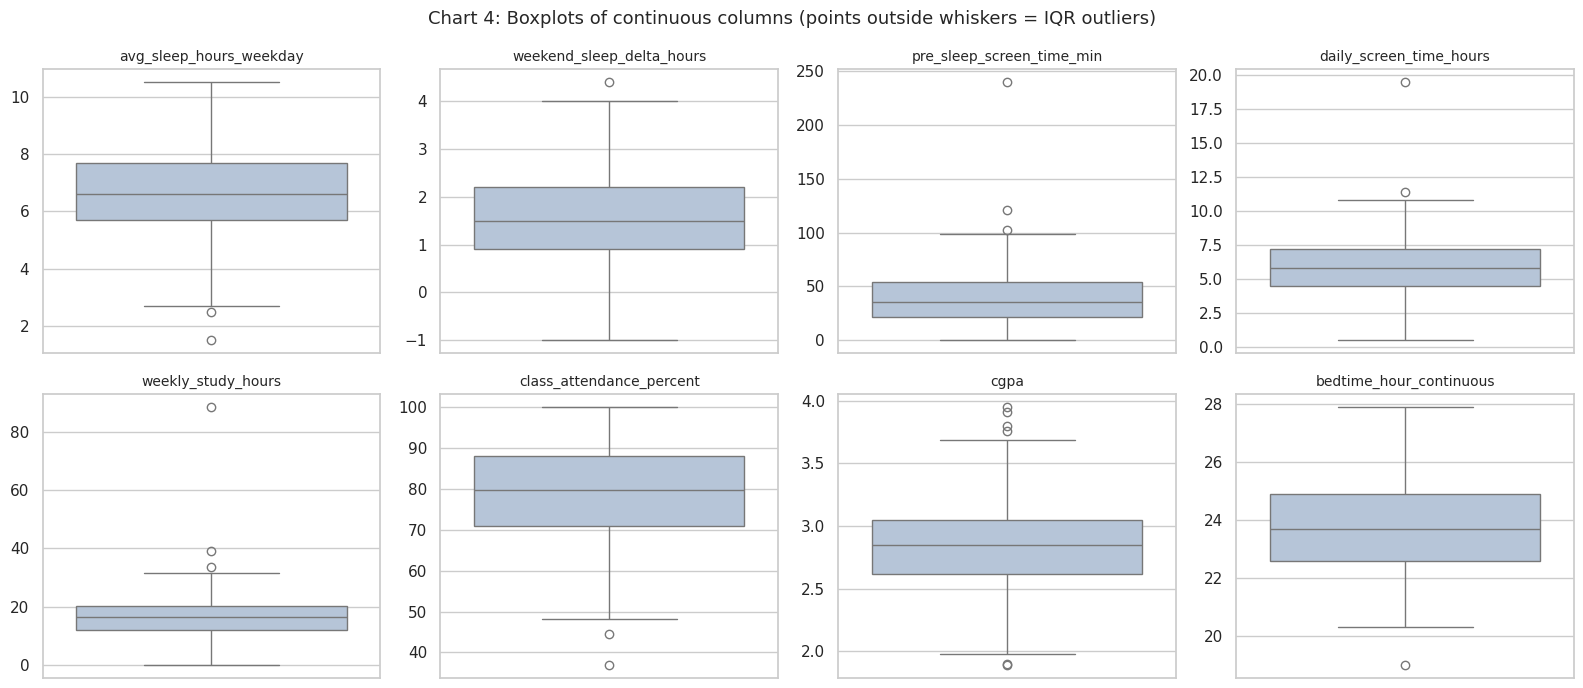

In [10]:
outlier_cols = [
    "avg_sleep_hours_weekday", "weekend_sleep_delta_hours", "pre_sleep_screen_time_min",
    "daily_screen_time_hours", "weekly_study_hours", "class_attendance_percent",
    "cgpa", "bedtime_hour_continuous",
]

rows = []
bounds = {}
for col in outlier_cols:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    bounds[col] = (low, high)
    n_low = (df_clean[col] < low).sum()
    n_high = (df_clean[col] > high).sum()
    rows.append([col, round(low, 2), round(high, 2), n_low, n_high,
                 df_clean[col].min(), df_clean[col].max()])

outlier_table = pd.DataFrame(rows, columns=["Column", "Lower bound", "Upper bound", "# below", "# above", "Min", "Max"])
print(outlier_table.to_string(index=False))

# Chart 4: boxplots (one panel per column because the scales are very different)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flatten(), outlier_cols):
    sns.boxplot(y=df_clean[col], ax=ax, color="lightsteelblue")
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("")
fig.suptitle("Chart 4: Boxplots of continuous columns (points outside whiskers = IQR outliers)", fontsize=13)
plt.tight_layout()
plt.show()

**Observation:** The most extreme values are in `weekly_study_hours` (max 88.5 hours per week, which is more than 12 hours every day), `daily_screen_time_hours` (max 19.5 hours), `pre_sleep_screen_time_min` (max 240 minutes) and `avg_sleep_hours_weekday` (min 1.5 hours as a regular weekday average). These are not believable as typical student behaviour and look like entry errors.

**Handling decisions and reasons:**
- **Capped** (winsorised to the IQR bounds): `weekly_study_hours`, `daily_screen_time_hours`, `pre_sleep_screen_time_min`, `avg_sleep_hours_weekday`. Capping keeps the student's record (and the direction: "very high" stays "high") while stopping a few impossible values from distorting the mean and correlations. Deleting the rows would also remove otherwise valid answers.
- **Kept:** `cgpa` (all values between 1.89 and 3.95 are valid CGPAs), `class_attendance_percent` (low attendance is real), `weekend_sleep_delta_hours` and `bedtime_hour_continuous` (late sleepers are real behaviour, and the values are plausible).

In [11]:
cap_cols = ["weekly_study_hours", "daily_screen_time_hours", "pre_sleep_screen_time_min", "avg_sleep_hours_weekday"]

for col in cap_cols:
    low, high = bounds[col]
    low = max(low, 0)  # these values cannot be negative
    n_changed = ((df_clean[col] < low) | (df_clean[col] > high)).sum()
    df_clean[col + "_was_capped"] = (df_clean[col] < low) | (df_clean[col] > high)
    df_clean[col] = df_clean[col].clip(lower=low, upper=high)
    print(f"{col}: {n_changed} values capped to [{low:.2f}, {high:.2f}]")

df_clean[cap_cols].describe().T[["min", "max", "mean"]]

weekly_study_hours: 3 values capped to [0.00, 32.70]
daily_screen_time_hours: 2 values capped to [0.45, 11.25]
pre_sleep_screen_time_min: 3 values capped to [0.00, 102.00]
avg_sleep_hours_weekday: 2 values capped to [2.70, 10.70]


,min,max,mean
weekly_study_hours,0.0,32.70,16.484584
daily_screen_time_hours,0.5,11.25,5.809331
pre_sleep_screen_time_min,0.0,102.00,38.115619
avg_sleep_hours_weekday,2.7,10.50,6.609533


## 4. Exploratory (Diagnostic) Charts

Charts that expose data problems are placed next to the issue they show:

| Chart | What it shows |
|---|---|
| Chart 1 (section 3.1) | Missing-value heatmap: where values are missing |
| Chart 2a/2b (section 3.2) | Inconsistent gender categories before and after cleaning |
| Chart 3 (section 3.2) | Bedtime split across midnight |
| Chart 4 (section 3.3) | Boxplots showing outliers |
| Chart 5 (section 5) | Group balance (gender and major) |

## 5. PII and Bias Risks

### PII (personally identifiable information)
- `student_id` identifies an individual student record. It is not a name, but it can be linked back to a person if matched with university records.
- `age`, `gender`, `year_of_study`, `major_category` and `residence_type` are quasi-identifiers. In a small group (for example, a non-binary student in Law) they can identify one person when combined.
- Sensitive attributes: `gender` (including "Prefer not to say") and `cgpa` are personal and sensitive.
- Minors: 41 students are under 18 (all aged 17), so consent from a parent or guardian may be required.

**How to handle:** replace student_id with an anonymous sequential ID and remove the original ID before sharing. Do not publish results for very small groups. Report age in ranges if the data is shared.

In [12]:
# Replace student_id with an anonymous sequential ID, then drop the original
if "student_id" in df_clean.columns:
    df_clean["anon_id"] = range(1, len(df_clean) + 1)
    df_clean = df_clean.drop(columns=["student_id"])

print("Students under 18:", (df_clean["age"] < 18).sum(), "of", len(df_clean))
print("\nAges of students under 18:")
print(df_clean[df_clean["age"] < 18]["age"].value_counts())

Students under 18: 41 of 493

Ages of students under 18:
age
17    41
Name: count, dtype: int64


### Bias risks: sampling bias and unbalanced groups

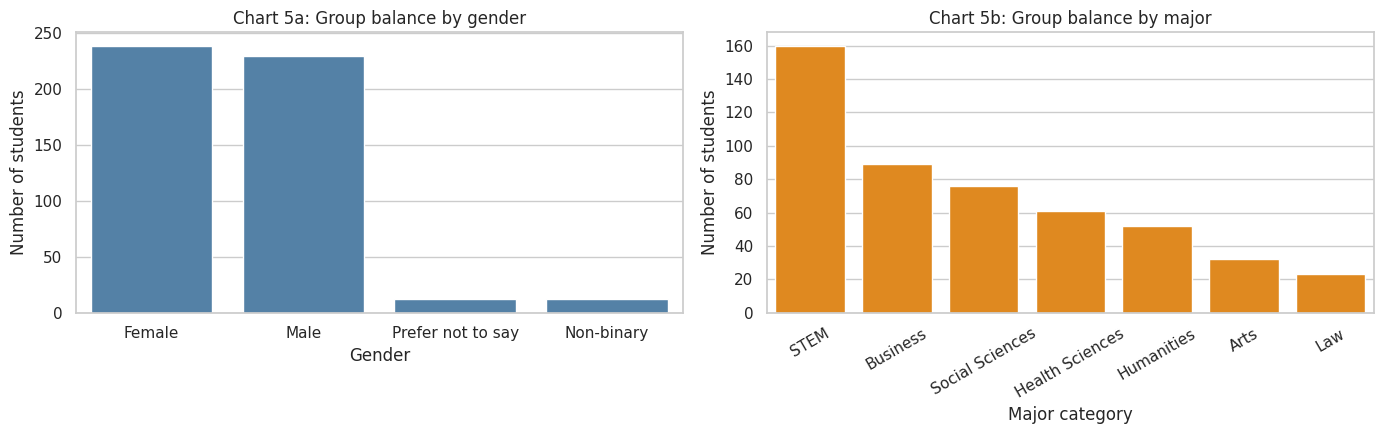

gender
Female               48.5
Male                 46.7
Prefer not to say     2.4
Non-binary            2.4
Name: proportion, dtype: float64

major_category
STEM               32.5
Business           18.1
Social Sciences    15.4
Health Sciences    12.4
Humanities         10.5
Arts                6.5
Law                 4.7
Name: proportion, dtype: float64

primary_device
Smartphone    54.4
Laptop        39.4
Tablet         6.3
Name: proportion, dtype: float64


In [13]:
# Chart 5: group balance
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

order_g = df_clean["gender"].value_counts().index
sns.countplot(data=df_clean, x="gender", order=order_g, ax=axes[0], color="steelblue")
axes[0].set_title("Chart 5a: Group balance by gender")
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Number of students")

order_m = df_clean["major_category"].value_counts().index
sns.countplot(data=df_clean, x="major_category", order=order_m, ax=axes[1], color="darkorange")
axes[1].set_title("Chart 5b: Group balance by major")
axes[1].set_xlabel("Major category")
axes[1].set_ylabel("Number of students")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

print((df_clean["gender"].value_counts(normalize=True) * 100).round(1))
print()
print((df_clean["major_category"].value_counts(normalize=True) * 100).round(1))
print()
print((df_clean["primary_device"].value_counts(normalize=True) * 100).round(1))

**Bias findings:**
- **Unbalanced groups:** Female and Male students make up about 95% of the sample, while "Non-binary" (12) and "Prefer not to say" (12) have only about 2.4% each. Any average for these two groups is unreliable because of the very small sample size.
- **Major imbalance:** STEM is the largest group (about 32%) and Law the smallest (about 5%), so overall results are dominated by STEM students.
- **Device imbalance:** most students use smartphones (about 54%), and tablet users are few (about 6%).
- **Sampling bias:** the data comes from a single source with no information on how students were selected (voluntary survey, one university?). It may not represent all university students. Sleep, screen time and study hours are also **self-reported**, so they may be inaccurate.

**How to handle:** report group sizes next to every group comparison, avoid conclusions about groups with fewer than about 30 students, combine tiny groups when needed (and say so), and state clearly that the results apply only to this sample.

## 6. Conclusion

### Fit-for-purpose check
Before concluding, we check whether the cleaned data still shows sensible relationships between sleep, screen time and CGPA.

                           bedtime_hour_continuous  avg_sleep_hours_weekday  pre_sleep_screen_time_min  daily_screen_time_hours  sleep_quality_score  weekly_study_hours  cgpa
bedtime_hour_continuous                       1.00                    -0.41                       0.39                     0.02                -0.34                0.06 -0.19
avg_sleep_hours_weekday                      -0.41                     1.00                      -0.33                    -0.02                 0.74               -0.05  0.44
pre_sleep_screen_time_min                     0.39                    -0.33                       1.00                     0.08                -0.48                0.05 -0.24
daily_screen_time_hours                       0.02                    -0.02                       0.08                     1.00                 0.01               -0.16 -0.03
sleep_quality_score                          -0.34                     0.74                      -0.48                     0.

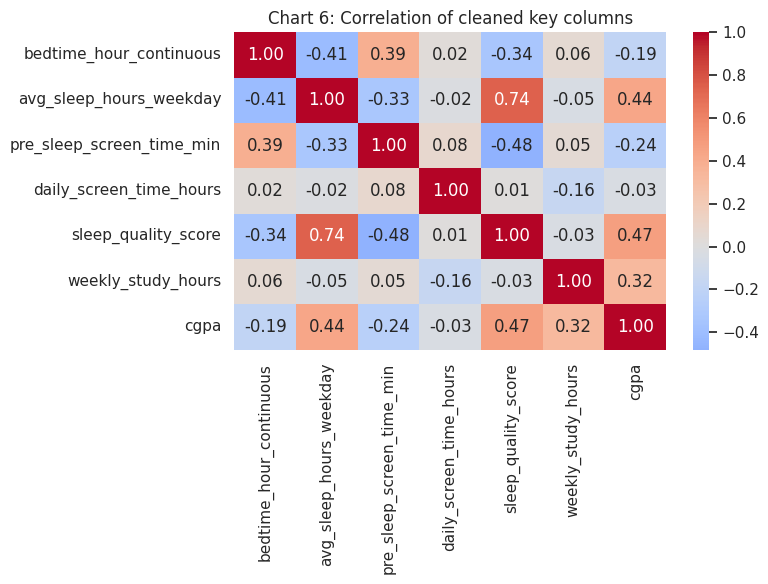

In [14]:
fit_cols = ["bedtime_hour_continuous", "avg_sleep_hours_weekday", "pre_sleep_screen_time_min",
            "daily_screen_time_hours", "sleep_quality_score", "weekly_study_hours", "cgpa"]
print(df_clean[fit_cols].corr().round(2).to_string())

plt.figure(figsize=(8, 6))
sns.heatmap(df_clean[fit_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Chart 6: Correlation of cleaned key columns")
plt.tight_layout()
plt.show()

**Is the data fit for the scenario?** Yes, after cleaning, with limits. We removed 7 rows with no CGPA, filled small gaps with documented methods, standardised gender labels, fixed the midnight bedtime problem, capped impossible extreme values and anonymised student IDs. As a sanity check, the cleaned data shows plausible relationships (CGPA with sleep quality about 0.47, with weekday sleep hours about 0.44, and with pre-sleep screen time about -0.24), which suggests the cleaning did not destroy the signal. These are correlations only, and capping and imputation may slightly affect them, so they are not results to report.

**Remaining limitations:**
1. 56 rows have an age that does not fit the year of study, and we cannot tell which field is wrong (flagged, not fixed).
2. Capped values (study, screen and sleep hours) are estimates, not the students' true answers (flagged in `*_was_capped` columns).
3. Median-filled values (`sleep_quality_score`, `energy_level`, `concentration_difficulty`) reduce natural variation slightly.
4. Very small groups (non-binary, prefer not to say, Law, tablet users) cannot support reliable comparisons.
5. All behaviour data is self-reported, the selection of students is unknown, and the dataset may be simulated, so findings cannot be generalised to all university students.
6. Students under 18 are in the data, so ethical and consent rules must be followed if the data is shared.

### Final data-quality check and export

In [15]:
# Report age in ranges in the shared file (age is a quasi-identifier)
df_clean["age_range"] = pd.cut(
    df_clean["age"],
    bins=[0, 17, 19, 21, 23, 100],
    labels=["17 or below", "18-19", "20-21", "22-23", "24+"],
)
df_export = df_clean.drop(columns=["age"])

print("Original shape:", df.shape)
print("Cleaned shape :", df_export.shape)
print("Missing values after cleaning:", df_export.isnull().sum().sum())
print("Duplicate rows after cleaning:", df_export.duplicated().sum())
print("\nGender categories:")
print(df_export["gender"].value_counts())

df_export.to_csv("student_sleep_screen_time_cleaned.csv", index=False)
print("\nSaved: student_sleep_screen_time_cleaned.csv")

Original shape: (500, 25)
Cleaned shape : (493, 34)
Missing values after cleaning: 0
Duplicate rows after cleaning: 0

Gender categories:
gender
Female               239
Male                 230
Prefer not to say     12
Non-binary            12
Name: count, dtype: int64

Saved: student_sleep_screen_time_cleaned.csv
